# Hypothesis Testing using Python

In this notebook, we'll explore three different questions which will have us implore three different statistcal tests from the cheatsheet. 

1. Question 1: Is the population mean FSIQ = 100?
2. Question 2: Is the population mean for FSIQ the same between men and women?
3. Question 3: Is there a difference between the durability of brand A shoes vs. brand B shoes.

We'll start by importing our first dataset, it's a toy dataset, so no cleaning is necessary. This just allows us to focus on the statistical analysis portion of the work!

## Importing Packages:

It's best to import all the necessary packages for the project in one code-block, don't scatter them throughout the Juypter Notebook file!

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats # Rather than importing the entire scipy stats library, we import just the stats module.

Here we are loading in the dataset <u>*iqdata.csv*</u>:

In [28]:
df = pd.read_csv("./iqdata.csv")
df.head()

,Nationality,Sex,FSIQ,VIQ,PIQ,MRI_Count
0,British,Female,133,132,124,816932
1,British,Male,140,150,124,1001121
2,British,Male,139,123,150,1038437
3,Spanish,Male,133,129,128,965353
4,British,Female,137,132,134,951545


Now we are identifying the unique categorical values within our dataset, as these are the groups that we can look to compare to one-another, whether that was comparing differences between Sex or Nationality (or both, something we will cover in Week 4):

In [29]:
print(f"The Types of Nationalities are: {df['Nationality'].unique()}")
print(f"The Sex of the Participants is: {df['Sex'].unique()}")

The Types of Nationalities are: <StringArray>
['British', 'Spanish', 'German', 'French']
Length: 4, dtype: str
The Sex of the Participants is: <StringArray>
['Female', 'Male']
Length: 2, dtype: str


<b> Data Overview: </b>

The data contains Nationality and Sex of different participants, as well as the IQ metrics for those individuals:

- FSIQ: Full Scale Intelligence Quotient
- VIQ: Verbal Intelligence Quotient
- PIQ: Performance Intelligence Quotient

Finally we have MRI Count, which is some metric to do with brain size in this instance.

## Question 1: Comparing a Variable to a Hypothetical Value

In this research, we would like to establish if the population mean for Full Scale Intelligence Quotient is equal to 100. 

This is a two-tailed test, we aren't asking if the FSIQ is greater than 100, or less than 100. We're asking if it's equal too. Hence the hypothesis statistically would be:

- $H_{0}: \mu = \mu_0$
- $H_{1}: \mu \neq \mu_0$

Where $\mu$ is the population mean for FSIQ, and $\mu_{0}$ is equal to 100. 


The appropriate test for this hypothesis would be a t-test (see cheat sheet), however the following assumptions must hold.

1. Scale of Measurement: The variable is continuous and measured on an interval or ratio scale.(True, FSIQ is a continuous variable).
2. Random Sampling: The data are obtained through random and independent sampling. (We can't test this, we assume it to be true)
3. Normality: The data comes from a normal distribution (using the Shaprio-Wilks statisical test, we can test if this is true).
4. Independence: Observations within the sample are independent of each other. (True, in this dataset, we haven't measured the FSIQ for an individual multiple times, each row is a unique, independent observation).

If any of these assumptions fail, then we will have to use the non-normally distributed version of the test:

- $H_{0}: \eta = \eta_0$
- $H_{1}: \eta \neq \eta_0$

Student Note 1: $\eta$ is the letter used to denote median in hypothesis testing.
Student Note 2: Observe the amount of writing I've put into laying out this question. This is incredible important, and is as important, if not more important than the code. Understanding and interpretation is key when completing statistical analysis.

---

### Assumption 3 - Normality

In the Shapiro-Wilk test, the null and alternative hypothesis is as follows:

- $H_0:$: *The data are normally distributed*
- $H_1:$: *The data are NOT normally distributed*

The $\alpha$ value is 5%. The fact that this is a two-tailed test, is arleady built into this test. So if $p < 0.05$ then we reject the null hypothesis.

In [30]:
# Part 1: Shapiro-Wilk test:
# ==========================
stats.shapiro(df["FSIQ"])

ShapiroResult(statistic=np.float64(0.8300553302840135), pvalue=np.float64(3.057070446944554e-05))

The outcome of our Shapiro-Wilk test would suggest that the p-value 0.0000305. Hence this is significantly lower than our critical value for $\alpha = 0.05$. Hence we reject the null hypothesis that the data is normally distributed, in favour for the alternative.

We can provide a visualization of the distribution of our data, by using a histogram.

<Axes: ylabel='Frequency'>

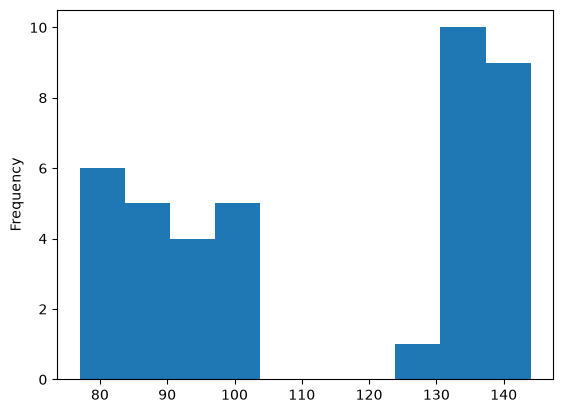

In [31]:
# Part 1: Visualize the Data
# ==========================
df["FSIQ"].plot(kind='hist')

The above plot does not appear to be normally distributed, there should be a central value, with tails either side. That looks like a "bell shape". This does not, supporting the evidence identified from our statistical analysis using the Shaprio-Wilk test.

Hence the test we will use for our hypothesis-test will be median-based, not mean-based.

### Hypothesis Test: Compare a Variable to a Hypothetical Value
Using Hypothesis testing, we will ivnestigate if the population MEDIAN for Full Scale Intelligence Quotient is equal to 100. 

- $H_{0}: \eta = \eta_0$
- $H_{1}: \eta \neq \eta_0$

We will utliize a critical value for $\alpha = 0.05$. Given that this is a two-tailed test, we will reject the null hypothesis if and only if $p < 0.025$

In [32]:
# Non-parametric Test: (Note: for this test, we must take away the value of n_0 from the variable)
stats.wilcoxon(df["FSIQ"] - 100)

WilcoxonResult(statistic=np.float64(180.5), pvalue=np.float64(0.003445390393057699))

Given That our p-value for our statistical analysis is less than 0.025, we can reject the null hypothesis that population median FSIQ is equal to 100, in favour for the alternative.

Let's create a visualization, that can provide supporting evidence to our statistical findings.

In [33]:
# If the data was normally distributed, we would use a one sample t-test
stats.ttest_1samp(df["FSIQ"], popmean=100)

TtestResult(statistic=np.float64(3.532307014238269), pvalue=np.float64(0.0010766792736967724), df=np.int64(39))

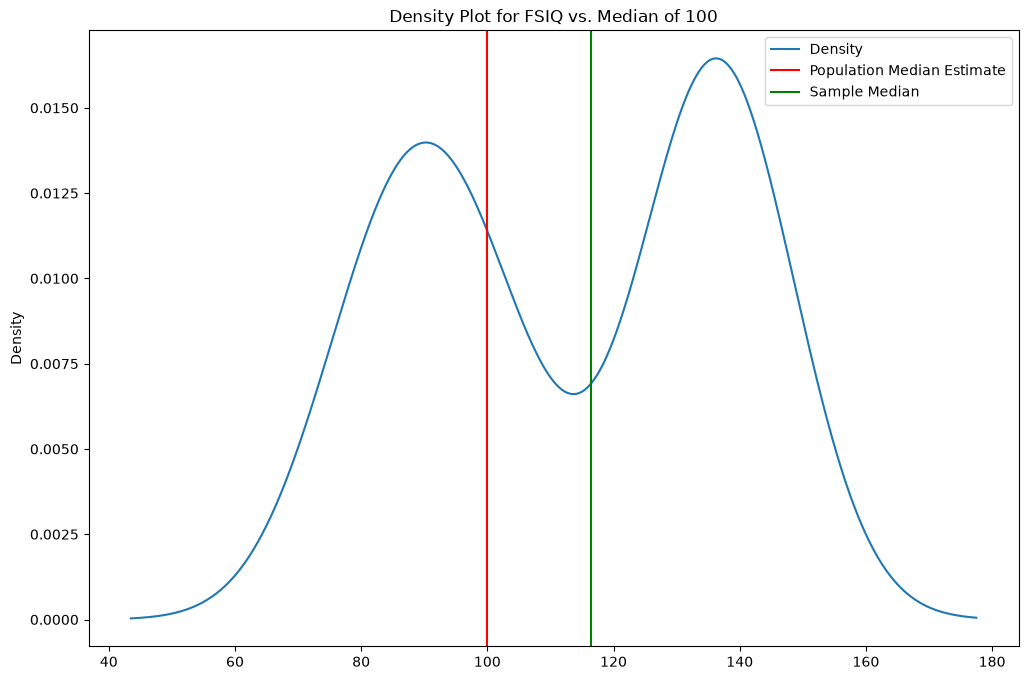

In [34]:
plt.figure(figsize=(12,8)) # Optional: Will increase the size of the figure

df["FSIQ"].plot(kind="density",
                title = "Density Plot for FSIQ vs. Median of 100",
                ylabel="Density",
                xlabel="FSIQ Score")

plt.axvline(x=100, color="r") # Use the wider matplotlib library to add additional functionality
plt.axvline(x=df["FSIQ"].median(), color="g")
plt.legend(["Density", "Population Median Estimate", "Sample Median"])

The visualization shows that a significant difference between the population median estimate and the sample median estimate, providing supporting evidence for our claim that the population median is not equal to 100, at the 5% significance level.

## Question 2: Comparing two Independent Variables

Note the above question I've written formally and in full-detail, and is closer to an example for how I would expect you to complete your statistical analysis. 

The below is more quick and put together for teaching material, you should be more expansive and investigatory in your writing regarding your hypothesis testing.

---

Suppose we wanted to answer the question: <b>"Is the population mean equal for FSIQ, different between men and women?"</b>

The hypothesis is as follows:

- $H_0: \mu_1 = \mu_2$
- $H_1: \mu_1 \neq \mu_2$

This is a two-tailed test, where we are comparing the mean FSIQ for men vs. the mean FSIQ for women. 

For the assumptions they are the same as the previous question, except for the following:
- Homogeneity of Variances: The population vairances is assumed to be equal for the two groups. (This can be tested using the Levene's test, which we'll discuss the theory of more next week)


In [35]:
# Split the dataframe into male and female:

male_criteria = df["Sex"] == "Male"
female_criteria = df["Sex"] == "Female"

male_df = df[male_criteria]
female_df = df[female_criteria]

In [36]:
male_df.head()

,Nationality,Sex,FSIQ,VIQ,PIQ,MRI_Count
1,British,Male,140,150,124,1001121
2,British,Male,139,123,150,1038437
3,Spanish,Male,133,129,128,965353
8,British,Male,89,93,84,904858
9,German,Male,133,114,147,955466


In [37]:
female_df.head()

,Nationality,Sex,FSIQ,VIQ,PIQ,MRI_Count
0,British,Female,133,132,124,816932
4,British,Female,137,132,134,951545
5,German,Female,99,90,110,928799
6,British,Female,138,136,131,991305
7,French,Female,92,90,98,854258


<b> Normally Distributed: </b>

I need to check if each group of data is normally distributed, as such I will run a <u>Shaprio-Wilk</u> normality test on both groups of data.

In [38]:
male_norm = stats.shapiro(male_df["FSIQ"])
female_norm = stats.shapiro(female_df["FSIQ"])

print(f"Male Data (Normality Test): \n{male_norm}\n")
print(f"Female Data (Normality Test): \n{female_norm}\n")

Male Data (Normality Test): 
ShapiroResult(statistic=np.float64(0.8203509906241665), pvalue=np.float64(0.0017663042550529011))

Female Data (Normality Test): 
ShapiroResult(statistic=np.float64(0.8195639688463072), pvalue=np.float64(0.0017170505838045862))



Given that the test has already failed the normality of data assumption, we don't need to test the homogeneity of variance, but just so you can see what this would look like:

In [39]:
stats.levene(male_df["FSIQ"], female_df["FSIQ"])

LeveneResult(statistic=np.float64(0.24447043811144256), pvalue=np.float64(0.6238422857062191))

You can see that given the p-value is very high (62%) it would pass this assumption! But because the data has already failed one assumption. Then we must work with non-normal test (median-based test).

**Hypothesis Test**

The null hypothesis of the test, assumes the data is normally distributed. At the 1% Significance level, we can reject the null hypothesis is favour for the alternative. That the data is not-normally distributed.

As such, we can need to utilize a <u>Non Parametric Test</u>: <b>Wilcoxon Mann Whitney test</b>

- H0: The FSIQ between the two groups is equal. (popmedian_male = popmedian_female)
- H1: The FSIQ between the two groups is not equal. (popmedian_male =/= popmedian_female)



In [40]:
stats.mannwhitneyu(male_df["FSIQ"], female_df["FSIQ"], alternative="two-sided")

MannwhitneyuResult(statistic=np.float64(238.5), pvalue=np.float64(0.30322291213080355))

At the 5% significant level, a p-value of 0.025 is required, hence we do not reject the null-hypothesis.
That the FSIQ between the two groups is equal. We can visualize this with a box-plot:

FSIQ    Axes(0.125,0.11;0.775x0.77)
dtype: object

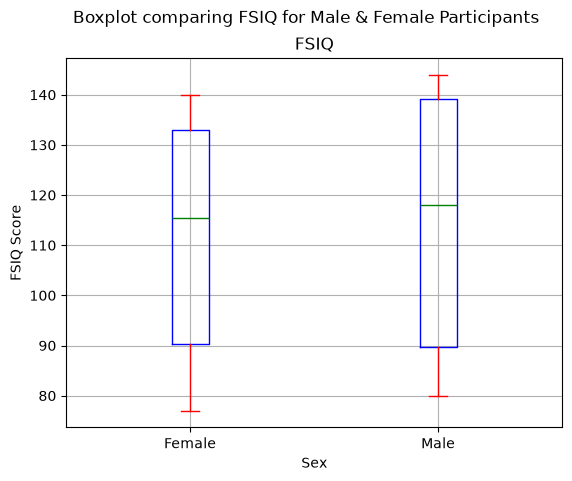

In [41]:
df.plot(kind="box", by="Sex", column="FSIQ", 
        color=dict(boxes='b', whiskers='r', medians='g', caps='r'),
        title="Boxplot comparing FSIQ for Male & Female Participants",
        ylabel="FSIQ Score",
        xlabel="Sex",
        grid=True)


Sex
Female    Axes(0.125,0.11;0.775x0.77)
Male      Axes(0.125,0.11;0.775x0.77)
Name: FSIQ, dtype: object

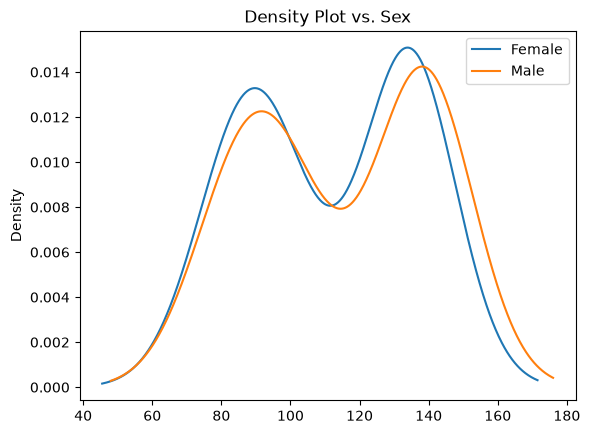

In [42]:
df.groupby("Sex")["FSIQ"].plot.kde(title="Density Plot vs. Sex",
                                   ylabel="Density",
                                   xlabel="FSIQ Score",
                                   legend=["Female", "Male"])

From the above data, we can see that the median values of both groups are contained inside one another, and that there is not a signficant difference between in the Q1, Q2 and Q3 values within the data.

As such this provides further supporting evidence for the resulting hypothesis test.

<Axes: title={'center': 'FSIQ'}, xlabel='Sex', ylabel='FSIQ Score'>

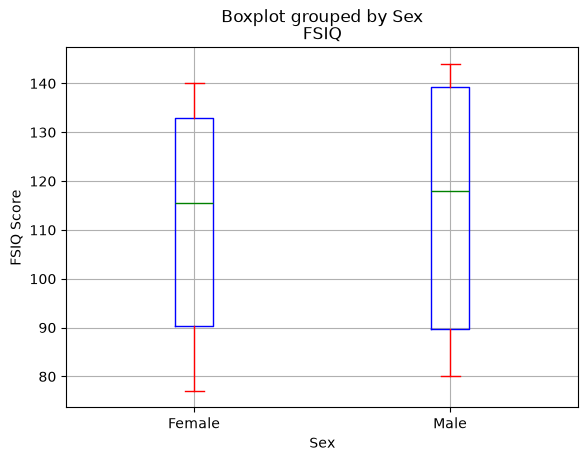

In [43]:
df.boxplot(by="Sex", column="FSIQ",
            color=dict(boxes='b', whiskers='r', medians='g', caps='r'),
            ylabel="FSIQ Score",
)

## Question 3: Compare two variables with the same response for the same subjects.

Question: Is there a difference between the durability of brand A shoes vs. brand B shoes.

This hypothesis is interseting, but if you look at this data below, each row is a single athelete that's tested two different pairs of shoes in the same way, by measuring how many weeks the shoes lasted before failure.

So here, we can see that what we have, is two variables, with the same response for the same subjects.


**[TASK] You'll be required to provide the writing around this question, similar to Question 1.**

In [44]:
shoes = pd.read_csv("./sport_shoes.csv")
shoes.head()

,branda,brandb
0,42,69
1,44,59
2,42,63
3,24,49
4,47,58


<Axes: title={'center': 'Density Plots Comparing Brand A & Brand B Shoes.'}, ylabel='Density'>

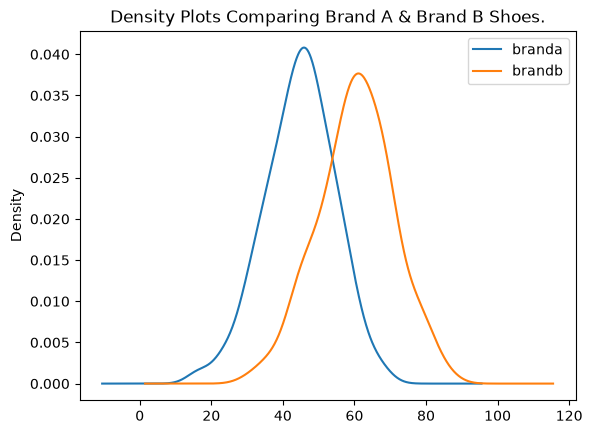

In [45]:
# Part 1: Test for Normality

shoes.plot(kind="density", column=["branda","brandb"],
        title="Density Plots Comparing Brand A & Brand B Shoes.")

It's not clear from the plots alone, if the data is significantly skewed, and whether or not if the sample could have been derived from a normal distribution or not. To clarify, a Shaprio-Wilks normality test will be conducted.

In [46]:
print(f"Shaprio-Wilk test of Normality (Brand A): \n{stats.shapiro(shoes['branda'])}")
print(f"Shaprio-Wilk test of Normality (Brand B): \n{stats.shapiro(shoes['brandb'])}")

Shaprio-Wilk test of Normality (Brand A): 
ShapiroResult(statistic=np.float64(0.9933531006332376), pvalue=np.float64(0.3318413013744468))
Shaprio-Wilk test of Normality (Brand B): 
ShapiroResult(statistic=np.float64(0.9951176325971979), pvalue=np.float64(0.6114007329262867))


In [47]:
print(f"Paired t-test (Difference: branda - brandb): \n{stats.ttest_rel(shoes['branda'], shoes['brandb'])}")

Paired t-test (Difference: branda - brandb): 
TtestResult(statistic=np.float64(-17.252594743526213), pvalue=np.float64(2.0690630639802934e-44), df=np.int64(249))


<Axes: title={'center': 'Boxplot for Longevity of Shoes vs. Brand'}, xlabel='Shoe Brand', ylabel='Longevity (Weeks)'>

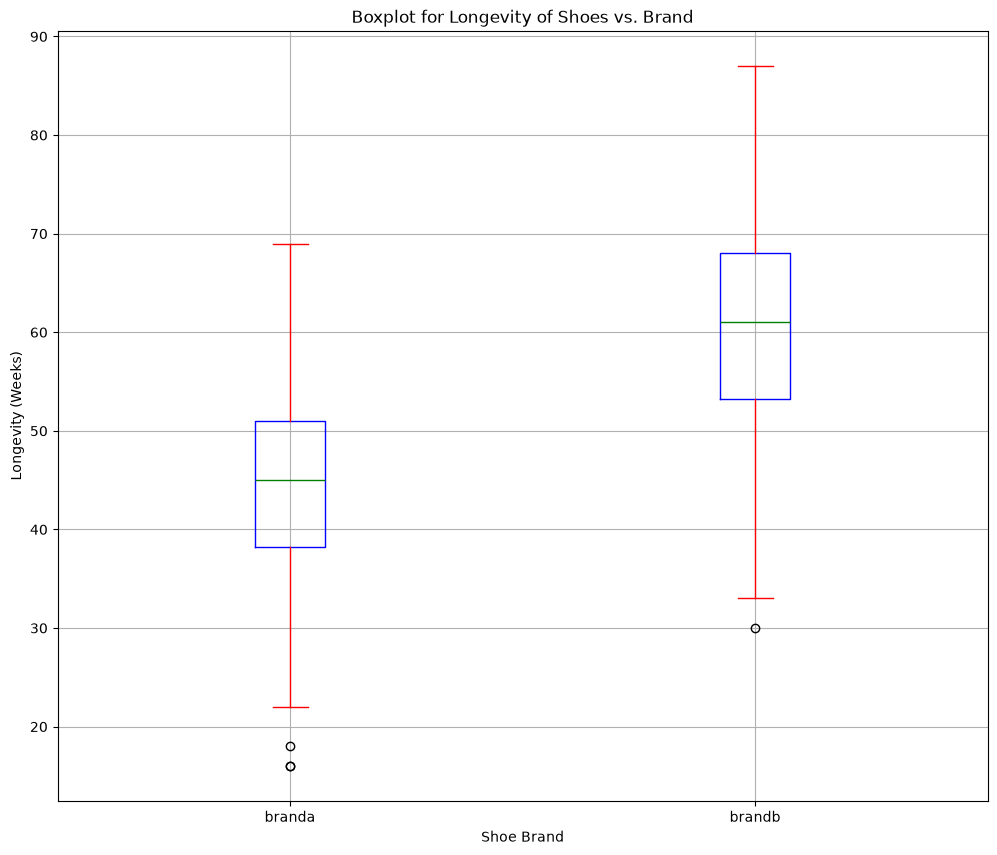

In [48]:
shoes.plot(kind="box", column=["branda","brandb"],
           title="Boxplot for Longevity of Shoes vs. Brand",
           xlabel="Shoe Brand",
           ylabel="Longevity (Weeks)",
           color=dict(boxes='b', whiskers='r', medians='g', caps='r'),
           figsize=(12,10),
           grid=True)

## Tutorials

You are ready for the tutorial questions, see the tutorial sheet for more!